# Broadened synthetic plane-front benchmark

## Research question

How does timing-uncertainty weighting affect angular reconstruction error across
different shower directions, station counts, and detector layouts?

This notebook reuses the production fitter in
`src/auger_reco/physics/plane_front.py`. It does not introduce a second
reconstruction implementation.

## Experimental controls

- Give weighted and uniform fits identical measurements within each trial.
- Keep the horizontal RMS array radius fixed across station counts.
- Include equal-uncertainty and heterogeneous-uncertainty conditions.
- Separate known simulated truth from the information supplied to the fitter.
- Record unsuccessful fits as well as successful fits in the later noisy study.
- Report favourable, unfavourable, and inconclusive comparisons.

| Factor | Values |
|---|---|
| True zenith | 15, 40, 60 degrees |
| True azimuth | 20, 110, 200, 290 degrees |
| Station count | 6, 12, 24 |
| Geometry | Random disk-derived layout; east-west stretched counterpart |
| Base layout realizations | Three predetermined layouts per station count |
| Timing uncertainties | Equal; heterogeneous |
| Horizontal RMS radius | Fixed at 1,000 m |

The factorial design contains

$$
3 \times 4 \times 3 \times 2 \times 3 \times 2 = 432
$$

scenarios, with two fitting methods per scenario.

These are **not 432 independent detector layouts**. We intentionally reuse
positions and uncertainty assignments across directions to make controlled
comparisons. The two geometry families also share each base random layout.

## Scope and limitations

This initial benchmark uses flat station arrays and a correctly specified
plane-front model. The subsequent noisy experiment will use independent,
zero-mean Gaussian timing errors with known standard deviations.

Curvature, terrain, outliers, and incorrectly estimated uncertainties are
separate experiments, not hidden changes to this baseline.

Different station counts use different layouts with matched spatial extent;
they do not represent successively adding stations to an unchanged array.
Matching one measure of extent does not make all geometric properties identical.

Results describe this controlled synthetic benchmark, not the performance
of the Pierre Auger Observatory on a real cosmic-ray population.

**Current scope:** configuration, exact-recovery checks, Gaussian-noise smoke tests,
paired Monte Carlo trials, conditional statistical comparisons, and archived results.
The outputs and run-status artifact identify which stages completed successfully.


## 1. Define the experiment before examining results

Use the project's Python environment for this notebook. The installed
`auger_reco` package supplies the production fitter.

### Read the next cell before running it

- `numpy` supplies arrays, vector calculations, and random-number generators.
- `pandas` organizes diagnostic results into tables.
- `product` produces every combination of the experimental settings.
- `plane_front` is our existing reconstruction module.
- `MASTER_SEED` fixes the random experiment reproducibly.
- Tuples such as `(6, 12, 24)` list the factor levels.
- `ARRAY_RMS_RADIUS_M` controls the array's horizontal spatial extent.
- `TIMING_RMS_SIGMA_NS` controls the mean timing-noise variance.
- `TRUE_ORIGIN_TIME_NS` is the known time at the coordinate origin used to
  generate measurements.
- The exact-recovery tolerances describe acceptable numerical error in
  noiseless tests; they are **not measurement uncertainties**.
- `FIT_OPTIONS` records the reconstruction settings. All other settings retain
  the production dataclass defaults; these must be archived alongside the
  experiment configuration in the later run metadata.

### The scenario record

`ScenarioSpec` describes one experimental condition.

- `@dataclass` automatically supplies a constructor from the declared fields.
- `frozen=True` prevents reassigning its fields after construction.
- `slots=True` restricts instances to their declared attributes.
- `Literal[...]` documents the accepted names for geometry and uncertainty
  profile; this annotation alone does not enforce them at runtime.
- `type FloatArray = NDArray[np.float64]` gives a short name to the type of
  floating-point NumPy arrays. This syntax requires Python 3.12 or later.

The final comprehension takes each combination from `product(...)`, unpacks
it into named variables, and constructs one `ScenarioSpec` using explicit
keyword arguments. The resulting tuple contains 432 scenarios, each to be
checked with two fit modes.


In [1]:
from dataclasses import dataclass
from itertools import product
from typing import Literal

import numpy as np
import pandas as pd
from numpy.typing import NDArray

from auger_reco.physics import plane_front

# Reproducible experimental settings.
MASTER_SEED = 20261010

STATION_COUNTS = (6, 12, 24)
GEOMETRIES = ("disk", "elongated")
LAYOUT_IDS = (0, 1, 2)

ZENITHS_DEG = (15.0, 40.0, 60.0)
AZIMUTHS_DEG = (20.0, 110.0, 200.0, 290.0)

UNCERTAINTY_PROFILES = ("equal", "heterogeneous")

# Physical scales for this controlled toy experiment.
ARRAY_RMS_RADIUS_M = 1_000.0
EAST_WEST_STRETCH = 4.0
TIMING_RMS_SIGMA_NS = 10.0
TRUE_ORIGIN_TIME_NS = 100_000.0

# Numerical tolerances for noiseless recovery, not measurement errors.
EXACT_ANGLE_TOLERANCE_DEG = 1.0e-6
EXACT_TIME_TOLERANCE_NS = 1.0e-5

FIT_OPTIONS = plane_front.PlaneFrontFitOptions(
    minimum_stations=6,
)

# A convenient name for NumPy arrays containing 64-bit floating-point values.
type FloatArray = NDArray[np.float64]


@dataclass(frozen=True, slots=True)
class ScenarioSpec:
    """One predeclared combination of synthetic experimental conditions."""

    geometry: Literal["disk", "elongated"]
    number_of_stations: int
    layout_id: int
    zenith_deg: float
    azimuth_deg: float
    uncertainty_profile: Literal["equal", "heterogeneous"]


SCENARIOS = tuple(
    ScenarioSpec(
        geometry=geometry,
        number_of_stations=count,
        layout_id=layout_id,
        zenith_deg=zenith,
        azimuth_deg=azimuth,
        uncertainty_profile=profile,
    )
    for geometry, count, layout_id, zenith, azimuth, profile in product(
        GEOMETRIES,
        STATION_COUNTS,
        LAYOUT_IDS,
        ZENITHS_DEG,
        AZIMUTHS_DEG,
        UNCERTAINTY_PROFILES,
    )
)

print(f"Predeclared scenarios: {len(SCENARIOS):,}")
print(f"Noiseless fits to check: {2 * len(SCENARIOS):,}")

Predeclared scenarios: 432
Noiseless fits to check: 864


## 2. Generate reproducible station geometries

### Physical motivation: control spatial extent

More stations can improve reconstruction, but a wider array can also improve
it: the same angular change can produce larger timing differences over a
longer baseline. Increasing count and width together would confound these
effects.

After centring each array, define its horizontal RMS radius by

$$
R_{\mathrm{RMS}}
=
\sqrt{\frac{1}{N}\sum_{i=1}^{N}(x_i^2+y_i^2)}.
$$

Multiplying every horizontal coordinate by
$1000\,\mathrm{m}/R_{\mathrm{RMS}}$ fixes this extent at 1,000 m while preserving
the layout's shape.

### Why the sampled radius uses a square root

For area-uniform points inside a unit disk, draw

$$
\alpha \sim U(0,2\pi), \qquad
U \sim U(0,1), \qquad
r=\sqrt{U}.
$$

The enclosed area grows as $r^2$. A uniform radius would put too many points
near the centre relative to an area-uniform distribution. Convert polar
coordinates to Cartesian coordinates with

$$
x=r\cos\alpha,\qquad y=r\sin\alpha.
$$

These are random **disk-derived** layouts, not perfectly symmetric circles.

### Random streams

`benchmark_rng(stream_id, *keys)` creates a reproducible generator:

- `stream_id` distinguishes purposes: 1 for geometry, 2 for uncertainty assignment.
- `*keys` collects additional integer identifiers.
- `SeedSequence` combines those identifiers with the master seed.
- `PCG64` explicitly selects the random-number-generation algorithm.
- Reusing the same keys reproduces a stream independently of scenario loop order.

Geometry does not depend on direction or uncertainty profile. The geometry
family is deliberately absent from its seed, so the elongated counterpart
starts from the same base layout.

### Follow the position function line by line

1. Read the station count and construct its layout-specific generator.
2. Draw one angle and radius per station.
3. `np.column_stack(...)` forms an $N\times2$ array of horizontal positions.
4. `xy.mean(axis=0)` calculates each coordinate column's mean.
5. Subtract those means to centre the array.
6. `xy[:, 0]` selects all x coordinates; multiply them by four for the
   east-west stretched family.
7. Reject an unknown geometry name rather than silently substituting a layout.
8. Sum squared coordinates across each row, average across stations, and take
   the square root to obtain the RMS radius.
9. Reject an invalid extent; otherwise rescale the layout to the target radius.
10. Add a zero z column to create the $N\times3$ station-position array.

The applied x-coordinate stretch is four. The realized principal-axis ratio
need not equal four because the base layout is random.

All stations have $z=0$ intentionally. This tests the production fitter's
rank-two geometry support; it is not a claim about actual Auger terrain.


In [2]:
def benchmark_rng(stream_id: int, *keys: int) -> np.random.Generator:
    """Use explicit integer keys so generation does not depend on loop order."""

    seed = np.random.SeedSequence(
        [MASTER_SEED, stream_id, *keys],
    )

    return np.random.Generator(np.random.PCG64(seed))


def make_station_positions(spec: ScenarioSpec) -> FloatArray:
    """Generate flat arrays with a fixed horizontal RMS radius."""

    count = spec.number_of_stations

    # Geometry family is deliberately absent: both families share a base layout.
    rng = benchmark_rng(1, count, spec.layout_id)

    polar_angles = rng.uniform(
        0.0,
        2.0 * np.pi,
        size=count,
    )

    # The square root gives area-uniform sampling inside a unit disk.
    radii = np.sqrt(rng.uniform(0.0, 1.0, size=count))

    xy = np.column_stack(
        (
            radii * np.cos(polar_angles),
            radii * np.sin(polar_angles),
        )
    )

    # Move the array centroid to the coordinate origin.
    xy -= xy.mean(axis=0)

    if spec.geometry == "elongated":
        xy[:, 0] *= EAST_WEST_STRETCH
    elif spec.geometry != "disk":
        raise ValueError(f"Unknown geometry: {spec.geometry}")

    rms_radius = float(np.sqrt(np.mean(np.sum(xy**2, axis=1))))

    if not np.isfinite(rms_radius) or rms_radius <= 0.0:
        raise ValueError("The generated layout has no finite spatial extent.")

    # Preserve the shape while giving every layout the same RMS extent.
    xy *= ARRAY_RMS_RADIUS_M / rms_radius

    # Flat arrays deliberately exercise the fitter's rank-two geometry support.
    return np.column_stack((xy, np.zeros(count)))

## 3. Generate uncertainties and the known direction

### Equal-uncertainty control

For every station in the equal-uncertainty profile,

$$
\sigma_i=10\,\mathrm{ns}.
$$

Therefore,

$$
\sum_i \frac{e_i^2}{\sigma_i^2}
=
\frac{1}{100\,\mathrm{ns}^2}\sum_i e_i^2.
$$

Multiplying an objective by a positive constant does not change its mathematical
minimizer. Weighted and uniform fits should therefore agree within numerical
tolerance under this control, including in the later noisy experiment.

### Heterogeneous uncertainties with matched mean variance

Start with dimensionless relative values $a_i$ spanning 0.5 to 2.0, shuffle
their station assignments, and set

$$
\sigma_i
=
10\,\mathrm{ns}
\frac{a_i}{\sqrt{\frac{1}{N}\sum_j a_j^2}}.
$$

Then

$$
\frac{1}{N}\sum_i \sigma_i^2=100\,\mathrm{ns}^2.
$$

Both uncertainty profiles have the same expected mean timing-noise variance.
This does not equate every measure of statistical information: their average
inverse variances differ.

The final heterogeneous uncertainties are **not literally 5--20 ns**, because
the RMS normalization changes their scale.

### Follow the uncertainty function

- `np.full(...)` produces an array with the same uncertainty at every station.
- Unknown profile names raise an error.
- A distinct RNG stream separates assignment from position generation.
- `np.linspace(0.5, 2.0, count)` supplies evenly spaced relative values.
- `rng.permutation(...)` shuffles their station assignments.
- `relative_sigmas**2` squares each value.
- Take the square root of their mean squared value and divide by that scale.

Assignments are reused across directions and paired geometry families. They
are generated independently of positions, but a finite layout may still have
a chance spatial association between uncertainty and location.

### Construct the sky-arrival direction

With zenith $\theta$ measured from upward z and azimuth $\phi$ measured from
positive x toward positive y,

$$
\mathbf{s}=
\begin{bmatrix}
\sin\theta\cos\phi\\
\sin\theta\sin\phi\\
\cos\theta
\end{bmatrix},
\qquad
\mathbf{u}=-\mathbf{s}.
$$

The sky vector points upward toward the arrival direction; the propagation
vector points downward.

`np.deg2rad(...)` converts degrees to radians, the units required by NumPy's
trigonometric functions. Unpacking assigns the two values to `theta` and
`phi`. `np.array(..., dtype=np.float64)` constructs the three-component vector.

We construct truth directly from this analytical expression instead of using
the fitter's angle helper, providing some independence between simulation
and reconstruction implementations.


In [3]:
def make_timing_uncertainties(spec: ScenarioSpec) -> FloatArray:
    """Match mean timing variance between equal and unequal uncertainty profiles."""

    count = spec.number_of_stations

    if spec.uncertainty_profile == "equal":
        return np.full(
            count,
            TIMING_RMS_SIGMA_NS,
            dtype=np.float64,
        )

    if spec.uncertainty_profile != "heterogeneous":
        raise ValueError(f"Unknown uncertainty profile: {spec.uncertainty_profile}")

    # A separate stream prevents uncertainty assignment from using geometry draws.
    rng = benchmark_rng(2, count, spec.layout_id)

    relative_sigmas = rng.permutation(np.linspace(0.5, 2.0, count))

    rms_scale = float(np.sqrt(np.mean(relative_sigmas**2)))

    return TIMING_RMS_SIGMA_NS * relative_sigmas / rms_scale


def make_true_sky_direction(spec: ScenarioSpec) -> FloatArray:
    """Construct truth analytically, independently of the fitter's angle helper."""

    theta, phi = np.deg2rad([spec.zenith_deg, spec.azimuth_deg])

    return np.array(
        [
            np.sin(theta) * np.cos(phi),
            np.sin(theta) * np.sin(phi),
            np.cos(theta),
        ],
        dtype=np.float64,
    )

## 4. Require exact recovery before adding noise

### The timing equation

The plane-front model is

$$
t_i=t_0+\frac{\mathbf{r}_i\cdot\mathbf{u}}{c}.
$$

Because the generator constructs the sky vector $\mathbf{s}=-\mathbf{u}$,
we generate exact measurements with

$$
t_i^{\mathrm{exact}}
=
t_0-\frac{\mathbf{r}_i\cdot\mathbf{s}_{\mathrm{true}}}{c}.
$$

The minus sign follows from the sky/propagation distinction; it is not a
change in convention.

`positions @ true_sky` calculates one dot product per station: an
$N\times3$ matrix multiplied by a length-three vector produces a length-$N$
array. Positions are in metres, and $c$ is in metres per nanosecond, so the
geometric delay is in nanoseconds.

### What the gate checks

For every scenario:

1. Confirm the position and uncertainty array shapes.
2. Require finite values and positive uncertainties.
3. Verify the coordinate centroid is approximately zero.
4. Verify the mean squared horizontal radius is $1000^2\,\mathrm{m}^2$.
5. Verify the mean squared uncertainty is $10^2\,\mathrm{ns}^2$.
6. Fit the same exact measurements using both weighting modes.
7. Check angular recovery and independently check the vector components.
8. Check all predicted times and the recovered origin time.

`enumerate(SCENARIOS)` supplies an index and its specification. The inner
loop chooses one weighting mode at a time. The fitter receives only positions,
times, uncertainties, and numerical options: **it is not given the true
direction**.

### Reading the numerical assertions

- `np.testing.assert_allclose(...)` checks approximate numerical equality.
- `rtol=0.0` disables a tolerance proportional to the compared value.
- `atol=...` supplies the absolute tolerance.
- `err_msg=context` identifies the scenario if recovery fails.
- Shape/finite/positive `assert` statements are notebook test assertions,
  not a replacement for the production fitter's input validation.
- Append a dictionary for each successful check, then construct a DataFrame.
- The final group-by table reports each method's **largest** numerical
  discrepancies, not its mean performance.

A failed noiseless gate stops execution for investigation; it must not be
silently dropped to improve results. The later noisy benchmark will explicitly
retain failure records and denominators.

Noiseless residuals and chi-square should be approximately **zero**.
A reduced chi-square near one is an approximate expectation for correctly
specified **noisy** observations, not a target for this gate.


In [4]:
exact_rows = []

for scenario_index, spec in enumerate(SCENARIOS):
    positions = make_station_positions(spec)
    sigmas = make_timing_uncertainties(spec)
    true_sky = make_true_sky_direction(spec)

    # Propagation is the negative of the upward sky-arrival vector.
    exact_times = TRUE_ORIGIN_TIME_NS - positions @ true_sky / plane_front.C_M_PER_NS

    # Check the generated measurements before calling the fitter.
    assert positions.shape == (spec.number_of_stations, 3)
    assert sigmas.shape == (spec.number_of_stations,)

    assert np.isfinite(positions).all()
    assert np.isfinite(sigmas).all()
    assert (sigmas > 0.0).all()

    np.testing.assert_allclose(
        positions.mean(axis=0),
        0.0,
        rtol=0.0,
        atol=1.0e-10,
    )

    np.testing.assert_allclose(
        np.mean(np.sum(positions[:, :2] ** 2, axis=1)),
        ARRAY_RMS_RADIUS_M**2,
        rtol=1.0e-12,
        atol=0.0,
    )

    np.testing.assert_allclose(
        np.mean(sigmas**2),
        TIMING_RMS_SIGMA_NS**2,
        rtol=1.0e-12,
        atol=0.0,
    )

    for weighting in ("timing", "uniform"):
        fit = plane_front.fit_plane_front(
            positions,
            exact_times,
            sigmas,
            weighting=weighting,
            options=FIT_OPTIONS,
        )

        error = plane_front.angular_separation_deg(
            fit.sky_direction,
            true_sky,
        )

        context = f"{spec}, weighting={weighting}"

        if not np.isfinite(error) or error > EXACT_ANGLE_TOLERANCE_DEG:
            raise AssertionError(f"Noiseless angular recovery failed: {context}: {error}")

        # Independently verify the recovered vector components.
        np.testing.assert_allclose(
            fit.sky_direction,
            true_sky,
            rtol=0.0,
            atol=2.0e-8,
            err_msg=context,
        )

        np.testing.assert_allclose(
            fit.predicted_times_ns,
            exact_times,
            rtol=0.0,
            atol=EXACT_TIME_TOLERANCE_NS,
            err_msg=context,
        )

        np.testing.assert_allclose(
            fit.origin_time_ns,
            TRUE_ORIGIN_TIME_NS,
            rtol=0.0,
            atol=EXACT_TIME_TOLERANCE_NS,
            err_msg=context,
        )

        exact_rows.append(
            {
                "scenario_index": scenario_index,
                "weighting": weighting,
                "angular_error_deg": error,
                "maximum_absolute_residual_ns": (fit.maximum_absolute_residual_ns),
                "geometry_condition": fit.surface_condition_number,
                "quality_flags": fit.quality_flags,
            }
        )

exact_recovery = pd.DataFrame(exact_rows)

assert len(exact_recovery) == 2 * len(SCENARIOS)

print(f"All {len(exact_recovery):,} noiseless recovery checks passed.")

display(
    exact_recovery.groupby("weighting")[
        [
            "angular_error_deg",
            "maximum_absolute_residual_ns",
        ]
    ].max()
)

All 864 noiseless recovery checks passed.


,angular_error_deg,maximum_absolute_residual_ns
weighting,,
timing,1.286675e-12,2.910383e-11
uniform,6.247139e-13,1.455192e-11


## Transition from exact recovery to noisy inference

Passing the gate establishes recovery within the stated numerical tolerances.
It does not yet establish noisy angular resolution or an advantage from weighting.
The following sections implement the noisy experiment using the same scenarios.

Only three base-layout realizations per station count are included. Results
remain conditional on these geometries and directions. Avoid interpreting
a pooled distribution as a realistic cosmic-ray population.


## 5. Add Gaussian timing noise: a paired, predeclared experiment

The noiseless test established recovery of exact plane-front times. We now model
measurement noise, not a different physical shower front:

$$
z_i^{(j)}\sim \mathcal{N}(0,1),\qquad
\epsilon_i^{(j)}=\sigma_i z_i^{(j)},\qquad
t_{i,\mathrm{obs}}^{(j)}=t_{i,\mathrm{exact}}+\epsilon_i^{(j)}.
$$

Here $i$ identifies a station and $j$ identifies a trial. Errors are independent
across stations and trials in this toy model. The standard deviations are the
same uncertainties supplied to both fitters. Correct uncertainty calibration
is an assumption here; testing incorrect uncertainties is a separate experiment.

For every trial, construct **one observed-time array** and give that same array
to both methods. Comparing fits of different random noise would obscure the
effect of weighting. Directions, layouts, and uncertainty profiles vary across
the predeclared scenarios; noise varies within each scenario.

### Fixed analysis choices

- 200 paired trials for each of 432 scenarios: 86,400 noisy events, 172,800 fits.
- Main noise stream 3; separate smoke-test stream 4; bootstrap stream 5.
- Numerical tie: angular-error difference no greater than $10^{-5}$ degrees.
- Equal-uncertainty control: fit-to-fit direction difference at most
  $10^{-5}$ degrees and predicted-time difference at most $10^{-3}$ ns.
- 2,000 paired bootstrap resamples and descriptive 95% percentile intervals.
- No scenario removal or trial-count adjustment based on favourable results.

These tolerances address solver round-off and stopping behaviour, not detector
resolution. They are deliberately much smaller than the simulated uncertainties.

A scenario's SHA-256 identifier is computed from its complete specification.
Its seed includes that identifier and trial index, so loop reordering does not
change a trial. Do not use Python's process-dependent built-in hash for seeds.

### Code walkthrough

The imports add filesystem handling, provenance, compressed result storage,
plotting, and package-version reporting. The constants freeze the experiment.
The root finder supports execution from either the repository or its notebooks
directory. The JSON writer refuses existing files by default and forbids
non-standard NaN/Infinity literals. A small sanitizer represents unavailable
diagnostic numbers as JSON null without mislabelling them as zero.


In [5]:
import gzip
import json
import platform
import subprocess
import sys
from dataclasses import asdict
from datetime import UTC, datetime
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

TRIALS_PER_SCENARIO = 200
BOOTSTRAP_RESAMPLES = 2_000
BOOTSTRAP_CONFIDENCE = 0.95
MINIMUM_BOOTSTRAP_PAIRS = 20
NUMERICAL_TIE_TOLERANCE_DEG = 1.0e-5
CONTROL_DIRECTION_TOLERANCE_DEG = 1.0e-5
CONTROL_TIME_TOLERANCE_NS = 1.0e-3
OBJECTIVE_RELATIVE_TOLERANCE = 1.0e-6
SMOKE_TRIALS_PER_SCENARIO = 2
METHODS = ("timing", "uniform")


def find_project_root() -> Path:
    """Find the repository without hard-coding a personal filesystem path."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "src/auger_reco/physics/plane_front.py"
        ).is_file():
            return candidate
    raise FileNotFoundError("Run this notebook from inside the project repository.")


def json_safe(value):
    """Convert NumPy diagnostics to strict JSON; unavailable numbers become null."""
    if isinstance(value, dict):
        return {str(key): json_safe(item) for key, item in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_safe(item) for item in value]
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    if isinstance(value, np.generic):
        return json_safe(value.item())
    if isinstance(value, float) and not np.isfinite(value):
        return None
    return value


def write_json(path: Path, payload, *, replace: bool = False) -> None:
    """Create an artifact; overwrite only an explicitly mutable status file."""
    with path.open("w" if replace else "x", encoding="utf-8") as handle:
        json.dump(json_safe(payload), handle, indent=2, allow_nan=False)
        handle.write("\n")


def scenario_id(spec: ScenarioSpec) -> str:
    """Stable identifier independent of tuple position or process hash salt."""
    payload = json.dumps(asdict(spec), sort_keys=True, separators=(",", ":"))
    return sha256(payload.encode("utf-8")).hexdigest()


def scenario_rng(spec: ScenarioSpec, stream_id: int, trial_id: int = 0) -> np.random.Generator:
    """Give each scenario, stream, and trial a stable independent seed."""
    words = np.frombuffer(bytes.fromhex(scenario_id(spec)), dtype="<u4").tolist()
    return benchmark_rng(stream_id, *words, trial_id)


def draw_timing_noise(
    spec: ScenarioSpec, sigmas: FloatArray, trial_id: int, *, stream_id: int = 3
) -> FloatArray:
    """Draw independent zero-mean Gaussian timing errors with station-specific SDs."""
    if trial_id < 0 or sigmas.shape != (spec.number_of_stations,):
        raise ValueError("Invalid trial index or uncertainty shape.")
    if not np.isfinite(sigmas).all() or (sigmas <= 0.0).any():
        raise ValueError("Timing uncertainties must be finite and positive.")
    return scenario_rng(spec, stream_id, trial_id).normal(loc=0.0, scale=sigmas, size=sigmas.shape)


PROJECT_ROOT = find_project_root()
NOTEBOOK_PATH = PROJECT_ROOT / "notebooks/04_benchmark_synthetic_plane_front.ipynb"
RUN_DIR = (
    PROJECT_ROOT
    / "reports/results"
    / ("synthetic_plane_benchmark_" + datetime.now(UTC).strftime("%Y%m%dT%H%M%S_%fZ"))
)
RUN_DIR.mkdir(parents=True, exist_ok=False)

assert len({scenario_id(spec) for spec in SCENARIOS}) == len(SCENARIOS)
scenario_lookup = {scenario_id(spec): spec for spec in SCENARIOS}
manifest = []
for spec in SCENARIOS:
    positions = make_station_positions(spec)
    sigmas = make_timing_uncertainties(spec)
    sky = make_true_sky_direction(spec)
    manifest.append(
        {
            "scenario_id": scenario_id(spec),
            **asdict(spec),
            "positions_m": positions,
            "timing_uncertainties_ns": sigmas,
            "true_sky_direction": sky,
            "exact_times_ns": TRUE_ORIGIN_TIME_NS - positions @ sky / plane_front.C_M_PER_NS,
        }
    )

configuration = {
    "created_utc": datetime.now(UTC).isoformat(),
    "master_seed": MASTER_SEED,
    "scenario_count": len(SCENARIOS),
    "trials_per_scenario": TRIALS_PER_SCENARIO,
    "bootstrap_resamples": BOOTSTRAP_RESAMPLES,
    "bootstrap_confidence": BOOTSTRAP_CONFIDENCE,
    "minimum_bootstrap_pairs": MINIMUM_BOOTSTRAP_PAIRS,
    "tie_tolerance_deg": NUMERICAL_TIE_TOLERANCE_DEG,
    "control_direction_tolerance_deg": CONTROL_DIRECTION_TOLERANCE_DEG,
    "control_time_tolerance_ns": CONTROL_TIME_TOLERANCE_NS,
    "objective_relative_tolerance": OBJECTIVE_RELATIVE_TOLERANCE,
    "array_rms_radius_m": ARRAY_RMS_RADIUS_M,
    "east_west_stretch": EAST_WEST_STRETCH,
    "timing_rms_sigma_ns": TIMING_RMS_SIGMA_NS,
    "true_origin_time_ns": TRUE_ORIGIN_TIME_NS,
    "fit_options": asdict(FIT_OPTIONS),
    "seed_policy": "PCG64 SeedSequence([master_seed, stream, SHA256_spec_le_uint32s, trial])",
    "streams": {"geometry": 1, "uncertainty_assignment": 2, "main": 3, "smoke": 4, "bootstrap": 5},
    "python_executable": sys.executable,
    "python_version": platform.python_version(),
    "package_versions": {
        name: version(name) for name in ("numpy", "scipy", "pandas", "matplotlib", "ipykernel")
    },
    "git_head": subprocess.check_output(
        ["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT, text=True
    ).strip(),
    "git_status": subprocess.check_output(
        ["git", "status", "--short"], cwd=PROJECT_ROOT, text=True
    ).splitlines(),
    "source_sha256": {
        "plane_front.py": sha256(Path(plane_front.__file__).read_bytes()).hexdigest(),
        "notebook_file_at_run_start": sha256(NOTEBOOK_PATH.read_bytes()).hexdigest(),
    },
}
write_json(RUN_DIR / "configuration.json", configuration)
write_json(RUN_DIR / "scenario_manifest.json", manifest)
# Preserve the saved source used for this run; execution outputs are archived later.
with (RUN_DIR / "notebook_at_run_start.ipynb").open("xb") as handle:
    handle.write(NOTEBOOK_PATH.read_bytes())
write_json(RUN_DIR / "run_status.json", {"state": "configured"})
print(f"Run artifacts: {RUN_DIR}")
print(f"Main experiment: {len(SCENARIOS) * TRIALS_PER_SCENARIO:,} paired trials")

Run artifacts: /home/abdul_samad/projects/auger-direction-reconstruction/reports/results/synthetic_plane_benchmark_20261010T104612_802216Z
Main experiment: 86,400 paired trials


## 6. Fit a pair without losing failures or optimizer information

The helper below calls the **same production function** for both methods.
Neither the true direction nor the true time intercept is supplied as an
initializer. Truth is used only after a fit, to calculate its angular error.

The per-fit record stores angular error, timing diagnostics, solver status,
quality flags, and all optimizer-attempt diagnostics. Known reconstruction
failures and invalid numerical outputs become explicit failure rows.
Unexpected programming exceptions still stop execution rather than being
silently relabelled as scientific failures.

For a completed pair, define

$$
\Delta_j=\alpha_{\mathrm{uniform},j}-\alpha_{\mathrm{timing},j}.
$$

Positive values favour weighting. A difference within the predeclared numerical
tolerance is a tie. Failed pairs have no invented angular improvement.

The shared observed-time array is read-only, and a content hash checks that
neither call changed it. We also retain a hash of the actual noise and later
archive the full noise arrays, allowing replay without relying solely on seeds.

For equal uncertainties, compare fitted directions **directly**, not only their
angular errors relative to truth: two different directions can be equally far
from truth. Compare their predicted times as an additional control.

The uniform fit minimizes unweighted timing SSE. Its reported chi-square still
uses the physical timing uncertainties; it is a diagnostic, not its objective.


In [6]:
class InvalidFitOutputError(RuntimeError):
    """A returned fit contains unusable metrics for this benchmark."""


def fit_and_record(
    spec: ScenarioSpec,
    positions: FloatArray,
    observed: FloatArray,
    sigmas: FloatArray,
    truth: FloatArray,
    trial_id: int,
    weighting: plane_front.WeightingMode,
):
    """Return an auditable record and, when usable, the fitted result."""
    record = {
        "scenario_id": scenario_id(spec),
        "trial_id": trial_id,
        "weighting": weighting,
        "status": "failure",
        "angular_error_deg": None,
        "zenith_deg": None,
        "azimuth_deg": None,
        "chi_square": None,
        "reduced_chi_square": None,
        "rms_residual_ns": None,
        "degrees_of_freedom": None,
        "quality_flags": [],
        "optimizer_status": None,
        "optimizer_message": None,
        "optimizer_cost": None,
        "optimizer_optimality": None,
        "optimizer_nfev": None,
        "optimizer_njev": None,
        "initializer": None,
        "optimizer_attempts": [],
        "initializer_rejections": [],
        "exception_type": None,
        "exception_message": None,
    }
    try:
        result = plane_front.fit_plane_front(
            positions, observed, sigmas, weighting=weighting, options=FIT_OPTIONS
        )
        record.update(
            {
                "quality_flags": result.quality_flags,
                "optimizer_status": result.optimizer_status,
                "optimizer_message": result.optimizer_message,
                "optimizer_cost": result.optimizer_cost,
                "optimizer_optimality": result.optimizer_optimality,
                "optimizer_nfev": result.optimizer_function_evaluations,
                "optimizer_njev": result.optimizer_jacobian_evaluations,
                "initializer": result.initializer_used,
                "optimizer_attempts": [asdict(item) for item in result.optimizer_attempts],
                "initializer_rejections": result.initializer_rejections,
                "surface_condition_number": result.surface_condition_number,
                "final_jacobian_rank": result.final_jacobian_rank,
                "sky_direction": result.sky_direction,
                "optimizer_parameters": result.optimizer_parameters,
            }
        )
        # Validate returned arrays before deriving metrics or accepting a fit.
        arrays = (
            result.predicted_times_ns,
            result.residuals_ns,
            result.standardized_residuals,
            result.objective_residuals,
        )
        if any(
            np.asarray(array).shape != observed.shape or not np.isfinite(array).all()
            for array in arrays
        ):
            raise InvalidFitOutputError("Wrong shape or nonfinite residual/prediction array.")
        sky = np.asarray(result.sky_direction)
        if (
            sky.shape != (3,)
            or not np.isfinite(sky).all()
            or not np.isclose(np.linalg.norm(sky), 1.0, rtol=0.0, atol=1.0e-10)
        ):
            raise InvalidFitOutputError("Sky direction must be a finite unit three-vector.")
        if (
            not np.isfinite(result.residual_sum_squares_ns2)
            or result.residual_sum_squares_ns2 < 0.0
            or not np.isfinite(result.objective_sum_squares)
            or result.objective_sum_squares < 0.0
            or result.number_of_stations != observed.size
        ):
            raise InvalidFitOutputError("Invalid timing SSE, objective, or station count.")
        if (
            not np.allclose(
                result.residuals_ns,
                observed - result.predicted_times_ns,
                rtol=1.0e-10,
                atol=1.0e-8,
            )
            or not np.allclose(
                result.standardized_residuals,
                result.residuals_ns / sigmas,
                rtol=1.0e-10,
                atol=1.0e-10,
            )
            or not np.isclose(
                result.chi_square,
                np.sum(result.standardized_residuals**2),
                rtol=1.0e-10,
                atol=1.0e-10,
            )
        ):
            raise InvalidFitOutputError("Returned timing diagnostics are inconsistent.")
        error = plane_front.angular_separation_deg(result.sky_direction, truth)
        metrics = [
            error,
            result.zenith_deg,
            result.azimuth_deg,
            result.chi_square,
            result.reduced_chi_square,
            result.rms_residual_ns,
        ]
        if (
            not np.isfinite(metrics).all()
            or result.predicted_times_ns.shape != observed.shape
            or not np.isfinite(result.predicted_times_ns).all()
            or not np.isfinite(result.residuals_ns).all()
            or result.final_jacobian_rank != 3
            or result.degrees_of_freedom <= 0
            or min(error, result.chi_square, result.rms_residual_ns) < 0.0
        ):
            raise InvalidFitOutputError("Nonfinite, negative, or unidentified fit metrics.")
        record.update(
            {
                "status": "success",
                "angular_error_deg": error,
                "zenith_deg": result.zenith_deg,
                "azimuth_deg": result.azimuth_deg,
                "chi_square": result.chi_square,
                "reduced_chi_square": result.reduced_chi_square,
                "rms_residual_ns": result.rms_residual_ns,
                "degrees_of_freedom": result.degrees_of_freedom,
            }
        )
        return json_safe(record), result
    except (
        plane_front.DegenerateStationGeometryError,
        plane_front.PlaneFrontInitializationError,
        plane_front.PlaneFrontOptimizationError,
        InvalidFitOutputError,
        FloatingPointError,
    ) as exc:
        record.update({"exception_type": type(exc).__name__, "exception_message": str(exc)})
        if hasattr(exc, "attempts"):
            record["optimizer_attempts"] = [asdict(item) for item in exc.attempts]
        if hasattr(exc, "rejected_initializers"):
            record["initializer_rejections"] = exc.rejected_initializers
        return json_safe(record), None


def run_pair(spec: ScenarioSpec, trial_id: int, *, stream_id: int = 3):
    """Give both methods the identical noisy observations; record their pairing."""
    positions = make_station_positions(spec)
    sigmas = make_timing_uncertainties(spec)
    truth = make_true_sky_direction(spec)
    exact = TRUE_ORIGIN_TIME_NS - positions @ truth / plane_front.C_M_PER_NS
    noise = draw_timing_noise(spec, sigmas, trial_id, stream_id=stream_id)
    observed = exact + noise
    if not np.isfinite(observed).all():
        raise ValueError("Generated observations must be finite.")
    for array in (positions, sigmas, observed):
        array.setflags(write=False)
    observed_digest = sha256(observed.tobytes()).hexdigest()

    records = []
    results = {}
    for method in METHODS:
        record, result = fit_and_record(spec, positions, observed, sigmas, truth, trial_id, method)
        if sha256(observed.tobytes()).hexdigest() != observed_digest:
            raise RuntimeError("A fitter changed the shared observed-time array.")
        records.append(record)
        results[method] = result

    paired = all(result is not None for result in results.values())
    pair = {
        "scenario_id": scenario_id(spec),
        "trial_id": trial_id,
        "paired_success": paired,
        "timing_success": results["timing"] is not None,
        "uniform_success": results["uniform"] is not None,
        "timing_angular_error_deg": records[0]["angular_error_deg"],
        "uniform_angular_error_deg": records[1]["angular_error_deg"],
        "improvement_deg": None,
        "outcome": "incomplete",
        "fit_separation_deg": None,
        "prediction_difference_ns": None,
        "equal_control_pass": None,
        "objective_order_pass": None,
        "noise_sha256": sha256(np.asarray(noise, dtype="<f8").tobytes()).hexdigest(),
    }
    if paired:
        delta = records[1]["angular_error_deg"] - records[0]["angular_error_deg"]
        separation = plane_front.angular_separation_deg(
            results["timing"].sky_direction, results["uniform"].sky_direction
        )
        time_difference = float(
            np.max(
                np.abs(results["timing"].predicted_times_ns - results["uniform"].predicted_times_ns)
            )
        )
        outcome = (
            "tie"
            if abs(delta) <= NUMERICAL_TIE_TOLERANCE_DEG
            else "timing_win"
            if delta > 0.0
            else "uniform_win"
        )
        objective_order_pass = results["timing"].chi_square <= results[
            "uniform"
        ].chi_square + OBJECTIVE_RELATIVE_TOLERANCE * (
            1.0 + results["uniform"].chi_square
        ) and results["uniform"].residual_sum_squares_ns2 <= results[
            "timing"
        ].residual_sum_squares_ns2 + OBJECTIVE_RELATIVE_TOLERANCE * (
            1.0 + results["timing"].residual_sum_squares_ns2
        )
        pair.update(
            {
                "objective_order_pass": objective_order_pass,
                "improvement_deg": delta,
                "outcome": outcome,
                "fit_separation_deg": separation,
                "prediction_difference_ns": time_difference,
            }
        )
        if spec.uncertainty_profile == "equal":
            pair["equal_control_pass"] = (
                separation <= CONTROL_DIRECTION_TOLERANCE_DEG
                and time_difference <= CONTROL_TIME_TOLERANCE_NS
            )
    return records, pair, noise

## 7. Smoke tests before the recorded experiment

The smoke test uses separate random draws and does not contribute to the main
results. It covers both geometries, all station counts, and both uncertainty
profiles at one predetermined direction and layout.

First verify reproducibility: regenerating a scenario/trial after an unrelated
draw must return exactly the same noise. A different trial must not reuse it.
Then check both fit modes succeed and the equal-uncertainty control holds.

A second check compares objectives. On the same data, the timing-weighted fit
should not have a larger chi-square than the uniform fit, and the uniform fit
should not have a larger unweighted timing SSE than the timing fit, apart from
the declared numerical tolerance. This checks optimization consistency; it
does not require the weighted direction to be closer to truth in every trial.

A smoke failure stops the main study. Its diagnostic records are saved first.


In [7]:
smoke_specs = [
    spec
    for spec in SCENARIOS
    if spec.layout_id == 0 and spec.zenith_deg == 40.0 and spec.azimuth_deg == 20.0
]
assert len(smoke_specs) == 12

probe = smoke_specs[0]
probe_sigmas = make_timing_uncertainties(probe)
first_draw = draw_timing_noise(probe, probe_sigmas, 0, stream_id=4)
_ = draw_timing_noise(smoke_specs[-1], make_timing_uncertainties(smoke_specs[-1]), 7)
np.testing.assert_array_equal(first_draw, draw_timing_noise(probe, probe_sigmas, 0, stream_id=4))
assert not np.array_equal(first_draw, draw_timing_noise(probe, probe_sigmas, 1, stream_id=4))

smoke_records = []
smoke_pairs = []
smoke_started = perf_counter()
for spec in smoke_specs:
    for trial_id in range(SMOKE_TRIALS_PER_SCENARIO):
        records, pair, _ = run_pair(spec, trial_id, stream_id=4)
        smoke_records.extend(records)
        smoke_pairs.append(pair)
smoke_elapsed = perf_counter() - smoke_started
write_json(RUN_DIR / "smoke_test.json", {"fits": smoke_records, "pairs": smoke_pairs})

assert all(pair["paired_success"] for pair in smoke_pairs), "Smoke fit failure: inspect artifacts."
assert all(pair["objective_order_pass"] for pair in smoke_pairs), "Objective consistency failed."
assert all(pair["equal_control_pass"] is not False for pair in smoke_pairs), (
    "Equal-uncertainty control failed."
)

print(f"Smoke tests passed: {len(smoke_pairs)} pairs, {2 * len(smoke_pairs)} fits.")
print(f"Smoke-test runtime: {smoke_elapsed:.2f} s; main trial count remains fixed.")

Smoke tests passed: 24 pairs, 48 fits.
Smoke-test runtime: 0.15 s; main trial count remains fixed.


## 8. Run and preserve every requested trial

For each scenario, allocate an array of shape
$(\mathrm{trials},\mathrm{stations})$ for the actual Gaussian noise. Each trial
calls the paired helper, writes complete optimizer diagnostics to compressed
JSON Lines, and retains compact records for analysis.

A JSON Lines file contains one JSON object per line. Compression keeps the
archive manageable while preserving every attempt. Successful and failed fits
both have records. Full noise arrays are saved separately in compressed NumPy
format, with scenario IDs as keys.

Progress messages report completed scenarios; they are not interim method
comparisons. Do not stop the run because one method appears ahead.

Each run uses a new timestamped directory. Rerunning this cell into the same
directory is deliberately refused; rerun the configuration cell to start a
separate experiment. If unexpected code errors occur, the status file records
an aborted run and the partial JSON Lines log remains available.

**Runtime:** the main experiment makes 172,800 production-fitter calls. This
is a CPU workload and can take several minutes. It does not require CUDA.


In [8]:
fit_log_path = RUN_DIR / "fit_records.jsonl.gz"
if fit_log_path.exists():
    raise FileExistsError("This run already has fit records. Start a new run from Section 5.")

write_json(RUN_DIR / "run_status.json", {"state": "running"}, replace=True)
compact_records = []
pair_records = []
noise_archive = {}
started = perf_counter()

try:
    with gzip.open(fit_log_path, "xt", encoding="utf-8") as log:
        for completed_scenarios, spec in enumerate(SCENARIOS, start=1):
            key = scenario_id(spec)
            scenario_noise = np.empty(
                (TRIALS_PER_SCENARIO, spec.number_of_stations), dtype=np.float64
            )
            for trial_id in range(TRIALS_PER_SCENARIO):
                records, pair, noise = run_pair(spec, trial_id)
                scenario_noise[trial_id] = noise
                pair_records.append(pair)
                for record in records:
                    log.write(json.dumps(record, allow_nan=False) + "\n")
                    compact_records.append(
                        {
                            name: value
                            for name, value in record.items()
                            if name
                            not in {
                                "optimizer_attempts",
                                "initializer_rejections",
                                "sky_direction",
                                "optimizer_parameters",
                            }
                        }
                    )
            noise_archive[key] = scenario_noise
            log.flush()
            if completed_scenarios % 12 == 0 or completed_scenarios == len(SCENARIOS):
                print(
                    f"Completed {completed_scenarios}/{len(SCENARIOS)} scenarios "
                    f"({completed_scenarios * TRIALS_PER_SCENARIO:,} pairs); "
                    f"elapsed {perf_counter() - started:.1f} s.",
                    flush=True,
                )
except (Exception, KeyboardInterrupt) as exc:
    write_json(
        RUN_DIR / "run_status.json",
        {
            "state": "aborted",
            "exception_type": type(exc).__name__,
            "message": str(exc),
            "pairs_recorded": len(pair_records),
        },
        replace=True,
    )
    raise

elapsed_seconds = perf_counter() - started
fit_results = pd.DataFrame(compact_records)
paired_trials = pd.DataFrame(pair_records)

expected_pairs = len(SCENARIOS) * TRIALS_PER_SCENARIO
assert len(fit_results) == 2 * expected_pairs
assert len(paired_trials) == expected_pairs
assert not fit_results.duplicated(["scenario_id", "trial_id", "weighting"]).any()
assert not paired_trials.duplicated(["scenario_id", "trial_id"]).any()
assert fit_results.groupby(["scenario_id", "weighting"]).size().eq(TRIALS_PER_SCENARIO).all()

# Detect source changes during a long run instead of mislabelling its provenance.
if (
    sha256(Path(plane_front.__file__).read_bytes()).hexdigest()
    != (configuration["source_sha256"]["plane_front.py"])
):
    raise RuntimeError("The production fitter changed during this experiment.")

fit_results.to_csv(RUN_DIR / "fit_metrics.csv.gz", index=False, compression="gzip")
paired_trials.to_csv(RUN_DIR / "paired_trials.csv.gz", index=False, compression="gzip")
np.savez_compressed(RUN_DIR / "timing_noise_draws.npz", **noise_archive)
exact_recovery.to_csv(RUN_DIR / "exact_recovery_checks.csv", index=False)

standard_noise = np.concatenate(
    [
        (noise_archive[scenario_id(spec)] / make_timing_uncertainties(spec)).ravel()
        for spec in SCENARIOS
    ]
)
noise_checks = {
    "number_of_station_noise_draws": int(standard_noise.size),
    "mean_noise_in_sigma": float(standard_noise.mean()),
    "standard_deviation_noise_in_sigma": float(standard_noise.std(ddof=1)),
}
write_json(RUN_DIR / "noise_generation_checks.json", noise_checks)
write_json(
    RUN_DIR / "run_status.json",
    {
        "state": "fits_complete",
        "pairs_recorded": len(paired_trials),
        "fits_recorded": len(fit_results),
        "elapsed_seconds": elapsed_seconds,
    },
    replace=True,
)
print("All requested trials recorded. Comparing outcomes next.")
display(pd.DataFrame([noise_checks]))

Completed 12/432 scenarios (2,400 pairs); elapsed 14.5 s.
Completed 24/432 scenarios (4,800 pairs); elapsed 30.0 s.
Completed 36/432 scenarios (7,200 pairs); elapsed 43.2 s.
Completed 48/432 scenarios (9,600 pairs); elapsed 58.2 s.
Completed 60/432 scenarios (12,000 pairs); elapsed 71.5 s.
Completed 72/432 scenarios (14,400 pairs); elapsed 86.7 s.
Completed 84/432 scenarios (16,800 pairs); elapsed 100.4 s.
Completed 96/432 scenarios (19,200 pairs); elapsed 115.8 s.
Completed 108/432 scenarios (21,600 pairs); elapsed 130.1 s.
Completed 120/432 scenarios (24,000 pairs); elapsed 146.6 s.
Completed 132/432 scenarios (26,400 pairs); elapsed 161.8 s.
Completed 144/432 scenarios (28,800 pairs); elapsed 177.9 s.
Completed 156/432 scenarios (31,200 pairs); elapsed 192.1 s.
Completed 168/432 scenarios (33,600 pairs); elapsed 207.9 s.
Completed 180/432 scenarios (36,000 pairs); elapsed 221.7 s.
Completed 192/432 scenarios (38,400 pairs); elapsed 237.3 s.
Completed 204/432 scenarios (40,800 pairs)

,number_of_station_noise_draws,mean_noise_in_sigma,standard_deviation_noise_in_sigma
0,1209600,0.000386,1.000686


## 9. Summarize conditional performance and Monte Carlo uncertainty

Two complementary tables are needed:

1. **Method summary:** each method's successful-fit angular-error median,
   68th and 95th percentiles, mean reduced chi-square, and success/failure counts.
2. **Paired summary:** comparisons restricted to trials where both methods
   returned usable results, with requested-trial and failure denominators retained.

The median paired improvement is

$$
\operatorname{median}_j
\left(\alpha_{\mathrm{uniform},j}-\alpha_{\mathrm{timing},j}\right),
$$

which is **not generally the difference between the two separate medians**.

For a bootstrap interval, sample complete paired differences with replacement,
calculate their median, and repeat 2,000 times. The 2.5th and 97.5th percentiles
form a descriptive 95% percentile interval. Fewer than 20 complete pairs yields
no interval, rather than an unjustified uncertainty estimate.

These intervals quantify Monte Carlo uncertainty **conditional on the chosen
layout, direction, uncertainty profile, and joint fit success**. They do not
measure generalization to all detector arrays. Hundreds of intervals are
exploratory and are not corrected for multiple comparisons.

With only 200 trials per scenario, a 95th percentile depends on roughly ten
upper-tail observations. Treat its small changes cautiously.

Win/loss/tie fractions use complete pairs as their denominator; failed pairs
are reported separately. No failure is assigned zero angular error.

The two-row grid overview is descriptive, not a real-event population estimate.
Its win fractions pool complete pairs and can change scenario weights when
failures occur. The scenario-level tables and equal-scenario plots remain
the primary comparisons.


In [9]:
def paired_median_interval(values: FloatArray, spec: ScenarioSpec) -> tuple[float, float]:
    """Percentile bootstrap of paired differences at a fixed experimental condition."""
    if values.size < MINIMUM_BOOTSTRAP_PAIRS:
        return np.nan, np.nan
    if not np.isfinite(values).all():
        raise ValueError("Bootstrap differences must be finite.")
    rng = scenario_rng(spec, 5)
    indices = rng.integers(0, values.size, size=(BOOTSTRAP_RESAMPLES, values.size))
    bootstrap_medians = np.median(values[indices], axis=1)
    tail = (1.0 - BOOTSTRAP_CONFIDENCE) / 2.0
    low, high = np.quantile(bootstrap_medians, [tail, 1.0 - tail])
    return float(low), float(high)


method_rows = []
for (key, method), group in fit_results.groupby(["scenario_id", "weighting"], sort=True):
    successful = group.loc[group["status"].eq("success")]
    errors = successful["angular_error_deg"].to_numpy(dtype=float)
    quantiles = np.quantile(errors, [0.5, 0.68, 0.95]) if errors.size else [np.nan] * 3
    method_rows.append(
        {
            "scenario_id": key,
            **asdict(scenario_lookup[key]),
            "weighting": method,
            "requested_trials": len(group),
            "successful_fits": len(successful),
            "failed_fits": len(group) - len(successful),
            "median_error_deg": quantiles[0],
            "p68_error_deg": quantiles[1],
            "p95_error_deg": quantiles[2],
            "mean_reduced_chi_square": successful["reduced_chi_square"].mean(),
            "mean_rms_residual_ns": successful["rms_residual_ns"].mean(),
        }
    )
method_summary = pd.DataFrame(method_rows)

comparison_rows = []
for key, group in paired_trials.groupby("scenario_id", sort=True):
    spec = scenario_lookup[key]
    valid = group.loc[group["paired_success"]]
    differences = valid["improvement_deg"].to_numpy(dtype=float)
    low, high = paired_median_interval(differences, spec)
    wins = int(valid["outcome"].eq("timing_win").sum())
    losses = int(valid["outcome"].eq("uniform_win").sum())
    ties = int(valid["outcome"].eq("tie").sum())
    complete = len(valid)
    assert wins + losses + ties == complete
    comparison_rows.append(
        {
            "scenario_id": key,
            **asdict(spec),
            "requested_trials": len(group),
            "complete_pairs": complete,
            "incomplete_pairs": len(group) - complete,
            "timing_failures": int((~group["timing_success"]).sum()),
            "uniform_failures": int((~group["uniform_success"]).sum()),
            "timing_wins": wins,
            "uniform_wins": losses,
            "numerical_ties": ties,
            "timing_win_fraction_of_complete": wins / complete if complete else np.nan,
            "uniform_win_fraction_of_complete": losses / complete if complete else np.nan,
            "tie_fraction_of_complete": ties / complete if complete else np.nan,
            "median_improvement_deg": np.median(differences) if complete else np.nan,
            "improvement_ci_low_deg": low,
            "improvement_ci_high_deg": high,
            "complete_pair_timing_median_deg": valid["timing_angular_error_deg"].median(),
            "complete_pair_uniform_median_deg": valid["uniform_angular_error_deg"].median(),
            "equal_control_failures": int(valid["equal_control_pass"].eq(False).sum()),
            "objective_order_failures": int(valid["objective_order_pass"].eq(False).sum()),
        }
    )
paired_summary = pd.DataFrame(comparison_rows)

grid_rows = []
for profile, group in paired_summary.groupby("uncertainty_profile", sort=True):
    complete = int(group["complete_pairs"].sum())
    grid_rows.append(
        {
            "uncertainty_profile": profile,
            "scenarios": len(group),
            "requested_pairs": int(group["requested_trials"].sum()),
            "complete_pairs": complete,
            "incomplete_pairs": int(group["incomplete_pairs"].sum()),
            "timing_win_fraction": group["timing_wins"].sum() / complete if complete else np.nan,
            "uniform_win_fraction": group["uniform_wins"].sum() / complete if complete else np.nan,
            "tie_fraction": group["numerical_ties"].sum() / complete if complete else np.nan,
            "median_of_scenario_median_improvements_deg": group["median_improvement_deg"].median(),
            "timing_median_of_scenario_medians_deg": group[
                "complete_pair_timing_median_deg"
            ].median(),
            "uniform_median_of_scenario_medians_deg": group[
                "complete_pair_uniform_median_deg"
            ].median(),
        }
    )
grid_summary = pd.DataFrame(grid_rows)

equal_cases = paired_summary.loc[paired_summary["uncertainty_profile"].eq("equal")]
control_checks = {
    "equal_uncertainty_control_failures": int(equal_cases["equal_control_failures"].sum()),
    "equal_uncertainty_incomplete_pairs": int(equal_cases["incomplete_pairs"].sum()),
    "objective_order_failures": int(paired_summary["objective_order_failures"].sum()),
    "incomplete_pairs_all_profiles": int(paired_summary["incomplete_pairs"].sum()),
}
controls_passed = all(
    control_checks[name] == 0
    for name in (
        "equal_uncertainty_control_failures",
        "equal_uncertainty_incomplete_pairs",
        "objective_order_failures",
    )
)

method_summary.to_csv(RUN_DIR / "method_summary_by_scenario.csv", index=False)
paired_summary.to_csv(RUN_DIR / "paired_summary_by_scenario.csv", index=False)
grid_summary.to_csv(RUN_DIR / "descriptive_grid_summary.csv", index=False)
write_json(RUN_DIR / "control_checks.json", control_checks)

display(grid_summary)
display(pd.DataFrame([control_checks]))
print("Control status:", "PASS" if controls_passed else "INVESTIGATE BEFORE INTERPRETING")

,uncertainty_profile,scenarios,requested_pairs,complete_pairs,incomplete_pairs,timing_win_fraction,uniform_win_fraction,tie_fraction,median_of_scenario_median_improvements_deg,timing_median_of_scenario_medians_deg,uniform_median_of_scenario_medians_deg
0,equal,216,43200,43200,0,0.000000,0.000000,1.000000,-1.066855e-16,0.139053,0.139053
1,heterogeneous,216,43200,43200,0,0.651204,0.348727,0.000069,2.560468e-02,0.114829,0.148150


,equal_uncertainty_control_failures,equal_uncertainty_incomplete_pairs,objective_order_failures,incomplete_pairs_all_profiles
0,0,0,0,0


Control status: PASS


## 10. Plot the experiment without selecting only favourable cases

### Reading the figures

1. **Error by station count and geometry:** every box summarizes the
   scenario-level median angular errors over the 36 direction/layout combinations
   for that geometry, count, and uncertainty profile. The boxes show variation
   across chosen scenarios, **not confidence intervals**. Both methods are shown.

2. **Directional sensitivity:** each heat-map pixel is the arithmetic mean of
   three layout-specific median paired improvements for one direction. Positive
   values favour weighting, negative values favour uniform fitting, and white
   is near zero. A pixel is missing if not all three layout summaries are
   available. This is a descriptive average over three chosen layouts, not a
   calibrated uncertainty estimate.

3. **Noise and a preselected example:** generated noise divided by its stated
   uncertainty should resemble a standard normal distribution. These are
   **injected noise values**, not fitted standardized residuals; fitting makes
   residuals correlated. The adjacent angular-error histogram uses one scenario
   chosen in the code before execution: disk geometry, 12 stations, layout 0,
   zenith 40 degrees, azimuth 20 degrees, heterogeneous uncertainties.

Histogram height counts observations per bin, not the total trial count.
Both methods use the same angular-error bin edges. The single example is an
illustration and does not replace the complete scenario tables.

All figures are saved at 180 dpi; the final poster can regenerate them at its
required physical dimensions and print resolution.


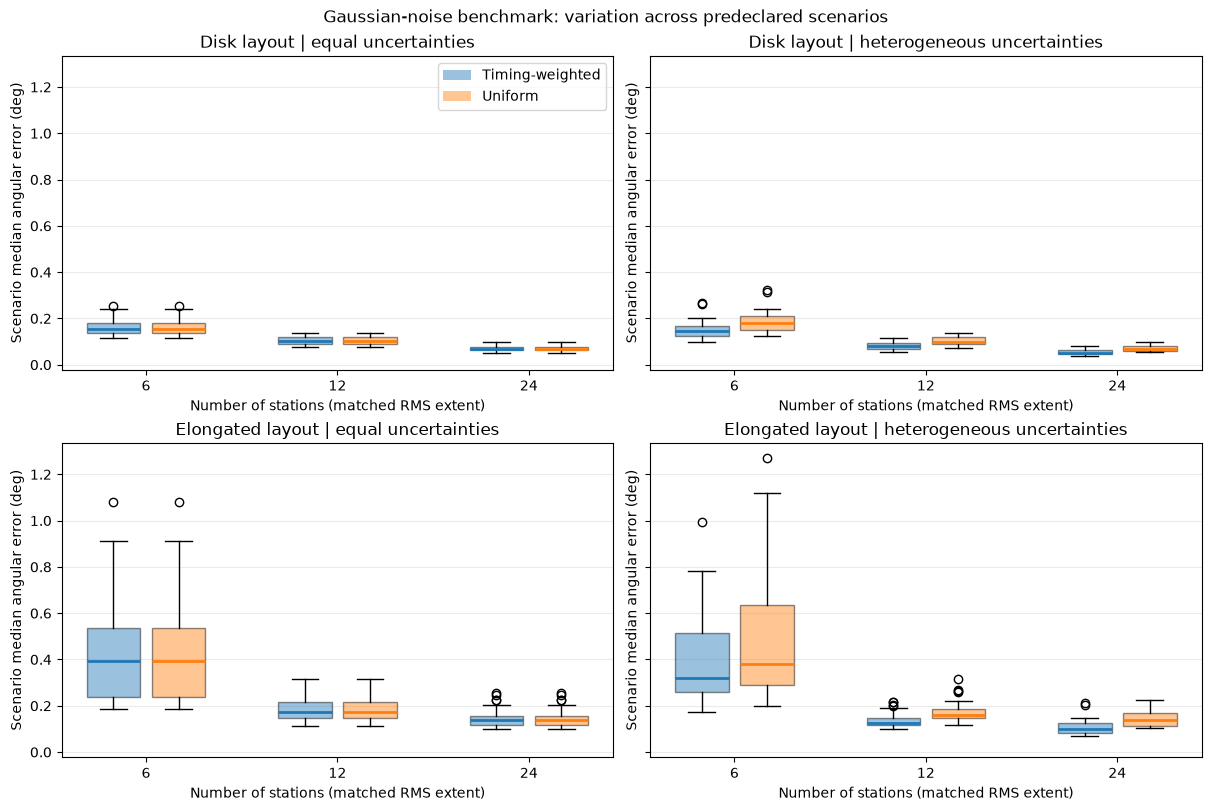

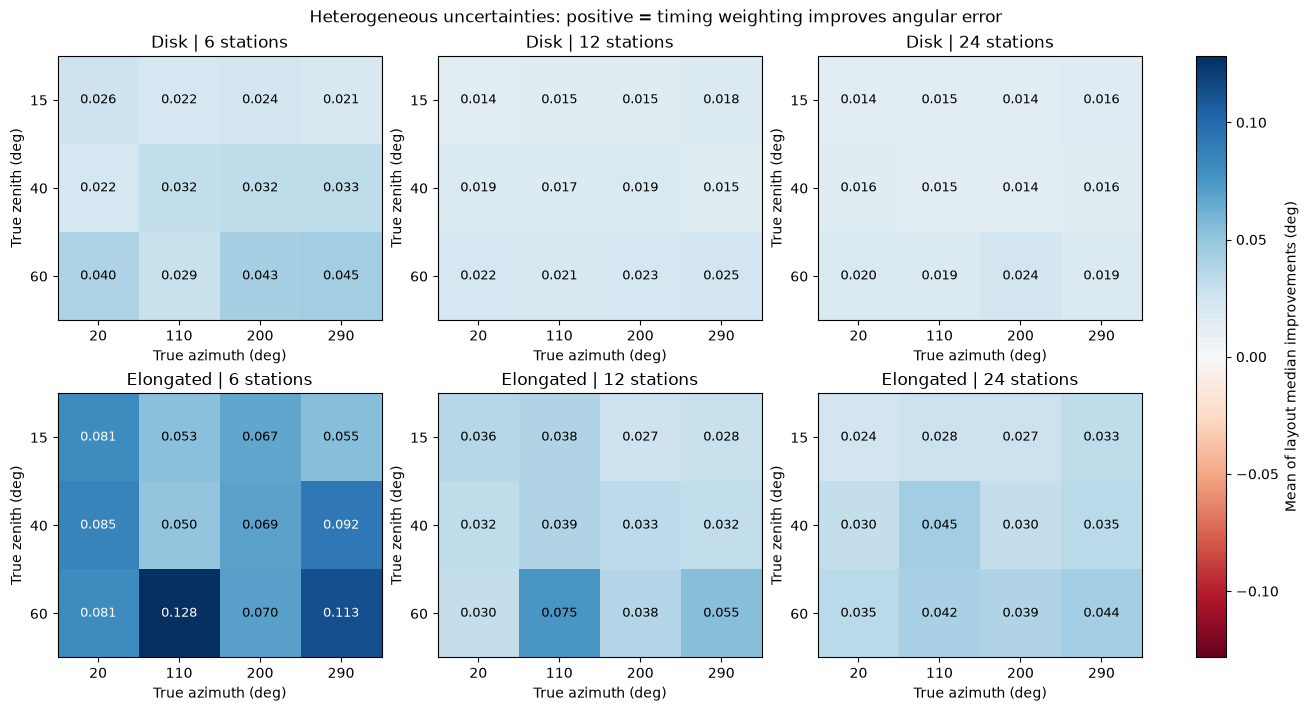

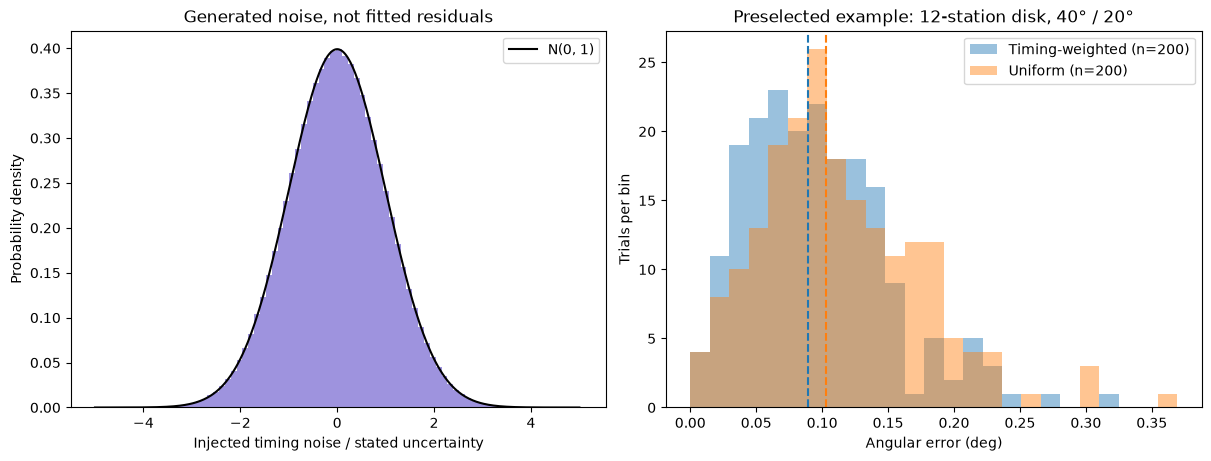

In [10]:
from matplotlib.patches import Patch

method_colors = {"timing": "tab:blue", "uniform": "tab:orange"}
method_labels = {"timing": "Timing-weighted", "uniform": "Uniform"}

fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained", sharey=True)
for row, geometry in enumerate(GEOMETRIES):
    for column, profile in enumerate(UNCERTAINTY_PROFILES):
        ax = axes[row, column]
        subset = method_summary.loc[
            method_summary["geometry"].eq(geometry)
            & method_summary["uncertainty_profile"].eq(profile)
        ]
        for method, offset in (("timing", -0.17), ("uniform", 0.17)):
            series = [
                subset.loc[
                    subset["number_of_stations"].eq(count) & subset["weighting"].eq(method),
                    "median_error_deg",
                ]
                .dropna()
                .to_numpy()
                for count in STATION_COUNTS
            ]
            ax.boxplot(
                series,
                positions=np.arange(len(STATION_COUNTS)) + offset,
                widths=0.28,
                manage_ticks=False,
                patch_artist=True,
                boxprops={"facecolor": method_colors[method], "alpha": 0.45},
                medianprops={"color": method_colors[method], "linewidth": 2},
            )
        ax.set_xticks(np.arange(len(STATION_COUNTS)), STATION_COUNTS)
        ax.set_title(f"{geometry.capitalize()} layout | {profile} uncertainties")
        ax.set_xlabel("Number of stations (matched RMS extent)")
        ax.set_ylabel("Scenario median angular error (deg)")
        ax.grid(axis="y", alpha=0.25)
axes[0, 0].legend(
    handles=[
        Patch(facecolor=method_colors[method], alpha=0.45, label=method_labels[method])
        for method in METHODS
    ]
)
fig.suptitle("Gaussian-noise benchmark: variation across predeclared scenarios")
fig.savefig(RUN_DIR / "angular_error_by_geometry_and_count.png", dpi=180)
plt.show()

heterogeneous = paired_summary.loc[paired_summary["uncertainty_profile"].eq("heterogeneous")]
heatmaps = {}
for geometry in GEOMETRIES:
    for count in STATION_COUNTS:
        subset = heterogeneous.loc[
            heterogeneous["geometry"].eq(geometry) & heterogeneous["number_of_stations"].eq(count)
        ]
        grouped = subset.groupby(["zenith_deg", "azimuth_deg"])["median_improvement_deg"].agg(
            ["mean", "count"]
        )
        grouped.loc[grouped["count"].ne(len(LAYOUT_IDS)), "mean"] = np.nan
        heatmaps[(geometry, count)] = (
            grouped["mean"].unstack().reindex(index=ZENITHS_DEG, columns=AZIMUTHS_DEG).to_numpy()
        )
finite_pixels = np.concatenate([array.ravel() for array in heatmaps.values()])
finite_pixels = finite_pixels[np.isfinite(finite_pixels)]
color_limit = max(float(np.max(np.abs(finite_pixels))) if finite_pixels.size else 0.0, 1e-6)
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout="constrained")
for row, geometry in enumerate(GEOMETRIES):
    for column, count in enumerate(STATION_COUNTS):
        ax = axes[row, column]
        values = heatmaps[(geometry, count)]
        image = ax.imshow(values, cmap="RdBu", vmin=-color_limit, vmax=color_limit, aspect="auto")
        ax.set_xticks(range(len(AZIMUTHS_DEG)), [f"{value:g}" for value in AZIMUTHS_DEG])
        ax.set_yticks(range(len(ZENITHS_DEG)), [f"{value:g}" for value in ZENITHS_DEG])
        ax.set_xlabel("True azimuth (deg)")
        ax.set_ylabel("True zenith (deg)")
        ax.set_title(f"{geometry.capitalize()} | {count} stations")
        for i, j in np.ndindex(values.shape):
            label = f"{values[i, j]:.3f}" if np.isfinite(values[i, j]) else "missing"
            color = "white" if abs(values[i, j]) > 0.6 * color_limit else "black"
            ax.text(j, i, label, ha="center", va="center", color=color, fontsize=9)
fig.colorbar(image, ax=axes.ravel().tolist(), label="Mean of layout median improvements (deg)")
fig.suptitle("Heterogeneous uncertainties: positive = timing weighting improves angular error")
fig.savefig(RUN_DIR / "paired_improvement_direction_heatmaps.png", dpi=180)
plt.show()

example_spec = ScenarioSpec("disk", 12, 0, 40.0, 20.0, "heterogeneous")
example = fit_results.loc[
    fit_results["scenario_id"].eq(scenario_id(example_spec)) & fit_results["status"].eq("success")
]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
axes[0].hist(standard_noise, bins=80, density=True, color="slateblue", alpha=0.65)
z = np.linspace(-5.0, 5.0, 401)
axes[0].plot(z, np.exp(-0.5 * z**2) / np.sqrt(2.0 * np.pi), color="black", label="N(0, 1)")
axes[0].set_xlabel("Injected timing noise / stated uncertainty")
axes[0].set_ylabel("Probability density")
axes[0].set_title("Generated noise, not fitted residuals")
axes[0].legend()
if not example.empty:
    upper = max(float(example["angular_error_deg"].max()), np.finfo(float).eps)
    bins = np.linspace(0.0, np.nextafter(upper, np.inf), 26)
    for method in METHODS:
        errors = example.loc[example["weighting"].eq(method), "angular_error_deg"].to_numpy()
        axes[1].hist(
            errors,
            bins=bins,
            alpha=0.45,
            color=method_colors[method],
            label=f"{method_labels[method]} (n={errors.size})",
        )
        if errors.size:
            axes[1].axvline(np.median(errors), color=method_colors[method], linestyle="--")
    axes[1].legend()
else:
    axes[1].text(0.5, 0.5, "No successful fits for the preselected example", ha="center")
axes[1].set_xlabel("Angular error (deg)")
axes[1].set_ylabel("Trials per bin")
axes[1].set_title("Preselected example: 12-station disk, 40° / 20°")
fig.savefig(RUN_DIR / "gaussian_noise_and_preselected_example.png", dpi=180)
plt.show()

## 11. Scientific conclusion and artifact inventory

Generate this conclusion from the recorded tables rather than manually typing
favourable numbers. The overview gives numerical controls, failure counts,
win/loss/tie denominators, and the spread of scenario-level outcomes.

The reported average reduced chi-square averages per-scenario means equally.
A weighted value near one is consistent with our correctly specified Gaussian
toy experiment; it is not a proof that a plane model describes real showers.
Uniform-fit chi-square is not the uniform objective.

All bootstrap intervals remain conditional and exploratory. Agreement here
does not explain or resolve the high chi-square of the real event. Controlled
curvature injection is the next physics experiment.

Artifacts include the fixed configuration, actual scenario arrays, actual
noise arrays, every fit attempt, paired outcomes, summary tables, plots, source
snapshot, and file hashes. The final status distinguishes completed analysis
from an aborted or incomplete run. No Git commit is performed by this notebook.


In [11]:
def scientific_number(value: float, digits: int = 6) -> str:
    """Avoid displaying an unavailable statistic as a numerical measurement."""
    return f"{value:.{digits}f}" if np.isfinite(value) else "unavailable"


heterogeneous_summary = paired_summary.loc[
    paired_summary["uncertainty_profile"].eq("heterogeneous")
]
positive_scenarios = int(
    heterogeneous_summary["median_improvement_deg"].gt(NUMERICAL_TIE_TOLERANCE_DEG).sum()
)
negative_scenarios = int(
    heterogeneous_summary["median_improvement_deg"].lt(-NUMERICAL_TIE_TOLERANCE_DEG).sum()
)
near_zero_scenarios = int(
    heterogeneous_summary["median_improvement_deg"].abs().le(NUMERICAL_TIE_TOLERANCE_DEG).sum()
)
missing_scenarios = int(heterogeneous_summary["median_improvement_deg"].isna().sum())

table_lines = [
    "| Uncertainty profile | Complete / requested pairs | Timing wins | Uniform wins | Ties |"
    " Median of scenario median improvements (deg) |",
    "|---|---:|---:|---:|---:|---:|",
]
for row in grid_summary.itertuples(index=False):
    table_lines.append(
        f"| {row.uncertainty_profile} | {row.complete_pairs:,} / {row.requested_pairs:,} | "
        f"{100 * row.timing_win_fraction:.2f}% | {100 * row.uniform_win_fraction:.2f}% | "
        f"{100 * row.tie_fraction:.2f}% | "
        f"{scientific_number(row.median_of_scenario_median_improvements_deg)} |"
    )

chi_lines = []
for (profile, method), group in method_summary.groupby(["uncertainty_profile", "weighting"]):
    chi_lines.append(
        f"- {profile}, {method_labels[method]}: mean of scenario mean reduced chi-square "
        f"= {scientific_number(group['mean_reduced_chi_square'].mean(), 4)}."
    )

control_statement = (
    "All recorded equal-uncertainty and objective-order controls passed."
    if controls_passed
    else "**At least one numerical control failed or was incomplete. Investigate the control "
    "table before interpreting method comparisons as validated results.**"
)
conclusion = (
    "# Broadened Gaussian timing-noise benchmark\n\n"
    f"Run directory: `{RUN_DIR.name}`.\n\n"
    f"The study used {len(SCENARIOS)} predeclared scenarios and "
    f"{TRIALS_PER_SCENARIO} paired trials per scenario: "
    f"{len(paired_trials):,} noisy synthetic events and {len(fit_results):,} fits. "
    "There were 18 geometry-family/count/layout combinations derived from nine base "
    "random layouts. Both methods received identical observations within each pair.\n\n"
    f"{control_statement} The full control results are in `control_checks.json`.\n\n"
    f"Timing-fit failures: {int(paired_summary['timing_failures'].sum()):,}; "
    f"uniform-fit failures: {int(paired_summary['uniform_failures'].sum()):,}; "
    f"incomplete pairs: {int(paired_summary['incomplete_pairs'].sum()):,}.\n\n"
    "## Descriptive balanced-grid comparison\n\n"
    + "\n".join(table_lines)
    + "\n\nWin fractions are conditional on complete pairs. These pooled percentages "
    "are descriptive, not a population estimate; failures can alter scenario weights. "
    "The last column gives equal weight to each available scenario median.\n\n"
    f"Among {len(heterogeneous_summary)} heterogeneous-uncertainty scenarios, "
    f"{positive_scenarios} had positive median paired improvement beyond the numerical "
    f"tie tolerance, {negative_scenarios} had negative improvement, "
    f"{near_zero_scenarios} were within tolerance, and {missing_scenarios} were unavailable. "
    "Positive improvement means the uniform error minus the timing-weighted error is positive.\n\n"
    "## Timing-model diagnostics\n\n"
    + "\n".join(chi_lines)
    + "\n\nThese are equal-scenario averages over successful fits. Weighted reduced "
    "chi-square is expected approximately near one under the correct Gaussian plane model. "
    "Uniform-fit chi-square remains an uncertainty-standardized diagnostic, not the "
    "uniform optimization objective.\n\n"
    f"Across {noise_checks['number_of_station_noise_draws']:,} generated station errors, "
    f"noise divided by its stated standard deviation had mean "
    f"{noise_checks['mean_noise_in_sigma']:.5f} and standard deviation "
    f"{noise_checks['standard_deviation_noise_in_sigma']:.5f}. "
    "These are injected errors, not post-fit residuals.\n\n"
    "## Interpretation and limits\n\n"
    "The experiment tests uncertainty weighting under a known, correctly specified "
    "plane-front model. Weighting need not win on every noise realization or every "
    "finite-sample scenario. The equal-uncertainty condition is a numerical control.\n\n"
    "Per-scenario paired-median bootstrap intervals are conditional Monte Carlo "
    "uncertainties, not uncertainties about arbitrary real detector arrays. They are "
    "exploratory and not multiplicity-adjusted. Each p95 estimate uses only roughly ten "
    "upper-tail trials and should not support precise rankings.\n\n"
    "Flat arrays, correctly calibrated independent Gaussian errors, matched RMS extent, "
    "three base layouts per count, and the selected directions limit generalization. "
    "Station-count layouts are not nested. Curvature, terrain, correlated errors, "
    "outliers, and misestimated uncertainties were not tested. No claim of improved "
    "real-Auger reconstruction or reduced real-event chi-square follows from this study.\n\n"
    "## Next physics experiment\n\n"
    "Introduce controlled shower-front curvature with known synthetic truth, evaluate "
    "the plane-model mismatch, and implement/test a curvature-aware fitter before "
    "returning to the real-event comparison.\n"
)
with (RUN_DIR / "scientific_conclusion.md").open("x", encoding="utf-8") as handle:
    handle.write(conclusion)

write_json(
    RUN_DIR / "run_status.json",
    {
        "state": "complete",
        "controls_passed": controls_passed,
        "scenario_count": len(SCENARIOS),
        "paired_trials": len(paired_trials),
        "fit_attempts": len(fit_results),
        "fitting_elapsed_seconds": elapsed_seconds,
        "completed_utc": datetime.now(UTC).isoformat(),
    },
    replace=True,
)
artifact_hashes = {
    path.name: sha256(path.read_bytes()).hexdigest()
    for path in sorted(RUN_DIR.iterdir())
    if path.is_file()
}
write_json(RUN_DIR / "artifact_hashes.json", artifact_hashes)
display(Markdown(conclusion))
print(f"Saved tables, diagnostics, noise arrays, plots, and conclusion in: {RUN_DIR}")

# Broadened Gaussian timing-noise benchmark

Run directory: `synthetic_plane_benchmark_20261010T104612_802216Z`.

The study used 432 predeclared scenarios and 200 paired trials per scenario: 86,400 noisy synthetic events and 172,800 fits. There were 18 geometry-family/count/layout combinations derived from nine base random layouts. Both methods received identical observations within each pair.

All recorded equal-uncertainty and objective-order controls passed. The full control results are in `control_checks.json`.

Timing-fit failures: 0; uniform-fit failures: 0; incomplete pairs: 0.

## Descriptive balanced-grid comparison

| Uncertainty profile | Complete / requested pairs | Timing wins | Uniform wins | Ties | Median of scenario median improvements (deg) |
|---|---:|---:|---:|---:|---:|
| equal | 43,200 / 43,200 | 0.00% | 0.00% | 100.00% | -0.000000 |
| heterogeneous | 43,200 / 43,200 | 65.12% | 34.87% | 0.01% | 0.025605 |

Win fractions are conditional on complete pairs. These pooled percentages are descriptive, not a population estimate; failures can alter scenario weights. The last column gives equal weight to each available scenario median.

Among 216 heterogeneous-uncertainty scenarios, 216 had positive median paired improvement beyond the numerical tie tolerance, 0 had negative improvement, 0 were within tolerance, and 0 were unavailable. Positive improvement means the uniform error minus the timing-weighted error is positive.

## Timing-model diagnostics

- equal, Timing-weighted: mean of scenario mean reduced chi-square = 1.0000.
- equal, Uniform: mean of scenario mean reduced chi-square = 1.0000.
- heterogeneous, Timing-weighted: mean of scenario mean reduced chi-square = 0.9994.
- heterogeneous, Uniform: mean of scenario mean reduced chi-square = 1.3641.

These are equal-scenario averages over successful fits. Weighted reduced chi-square is expected approximately near one under the correct Gaussian plane model. Uniform-fit chi-square remains an uncertainty-standardized diagnostic, not the uniform optimization objective.

Across 1,209,600 generated station errors, noise divided by its stated standard deviation had mean 0.00039 and standard deviation 1.00069. These are injected errors, not post-fit residuals.

## Interpretation and limits

The experiment tests uncertainty weighting under a known, correctly specified plane-front model. Weighting need not win on every noise realization or every finite-sample scenario. The equal-uncertainty condition is a numerical control.

Per-scenario paired-median bootstrap intervals are conditional Monte Carlo uncertainties, not uncertainties about arbitrary real detector arrays. They are exploratory and not multiplicity-adjusted. Each p95 estimate uses only roughly ten upper-tail trials and should not support precise rankings.

Flat arrays, correctly calibrated independent Gaussian errors, matched RMS extent, three base layouts per count, and the selected directions limit generalization. Station-count layouts are not nested. Curvature, terrain, correlated errors, outliers, and misestimated uncertainties were not tested. No claim of improved real-Auger reconstruction or reduced real-event chi-square follows from this study.

## Next physics experiment

Introduce controlled shower-front curvature with known synthetic truth, evaluate the plane-model mismatch, and implement/test a curvature-aware fitter before returning to the real-event comparison.


Saved tables, diagnostics, noise arrays, plots, and conclusion in: /home/abdul_samad/projects/auger-direction-reconstruction/reports/results/synthetic_plane_benchmark_20261010T104612_802216Z
